In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from fakenews.config import FIGURES_DIR
from fakenews.data import load_isot, load_welfake

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

isot = load_isot()
wel = load_welfake()
print(isot.shape, wel.shape)

(44898, 6) (72134, 4)


In [2]:
isot.head()

,title,text,label,dataset,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,fake,isot,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,fake,isot,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",fake,isot,News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",fake,isot,News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,fake,isot,News,"December 25, 2017"


In [3]:
wel.head()

,title,text,label,dataset
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,fake,welfake
1,NaN,Did they post their votes for Hillary already?,fake,welfake
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",fake,welfake
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,real,welfake
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",fake,welfake


In [4]:
print(isot.isna().sum())
print(wel.isna().sum())

title      0
text       0
label      0
dataset    0
subject    0
date       0
dtype: int64
title      558
text        39
label        0
dataset      0
dtype: int64


In [5]:
empty = isot["text"].str.strip() == ""
print(empty.sum())
isot.loc[empty, "label"].value_counts()

631


label
fake    630
real      1
Name: count, dtype: int64

In [6]:
print(isot.duplicated(subset=["title", "text"]).sum())
print(isot.duplicated(subset=["title"]).sum())

both = isot.groupby("text")["label"].nunique()
print((both > 1).sum())
print(isot.duplicated(subset=["text"]).sum())

5793
6169
1
6252


In [7]:
print(both[both > 1].index.tolist())
isot[isot.duplicated(subset=["title", "text"], keep=False)]["label"].value_counts()

[' ']


label
fake    10671
real      427
Name: count, dtype: int64

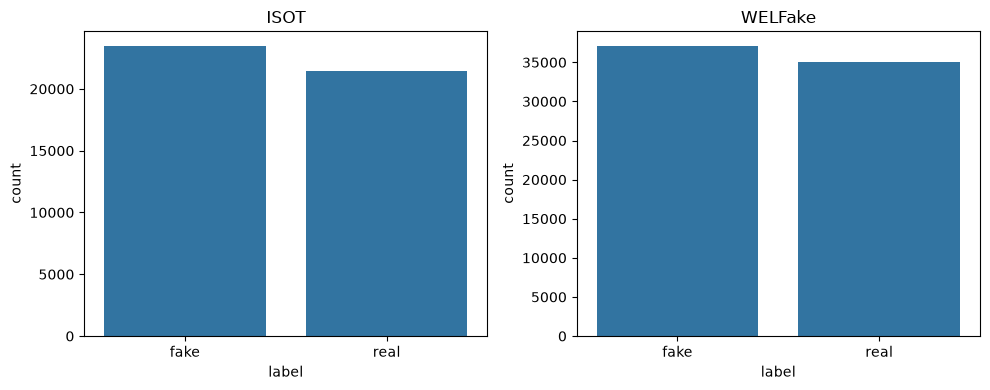

label
fake    0.523
real    0.477
Name: proportion, dtype: float64
label
fake    0.514
real    0.486
Name: proportion, dtype: float64


In [8]:
fig, axes = plt.subplots(1,2, figsize=(10,4))
sns.countplot(data=isot, x="label", ax=axes[0]).set_title("ISOT")
sns.countplot(data=wel, x="label", ax=axes[1]).set_title("WELFake")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_class_balance.png", dpi=120)
plt.show()

print(isot["label"].value_counts(normalize=True).round(3))
print(wel["label"].value_counts(normalize=True).round(3))

In [9]:
for df in (isot, wel):
  df["n_words"] = df["text"].fillna("").str.split().str.len()
  df["n_title_words"] = df["title"].fillna("").str.split().str.len()

isot.groupby("label")[["n_words", "n_title_words"]].median()

,n_words,n_title_words
label,,
fake,363.0,14.0
real,359.0,10.0


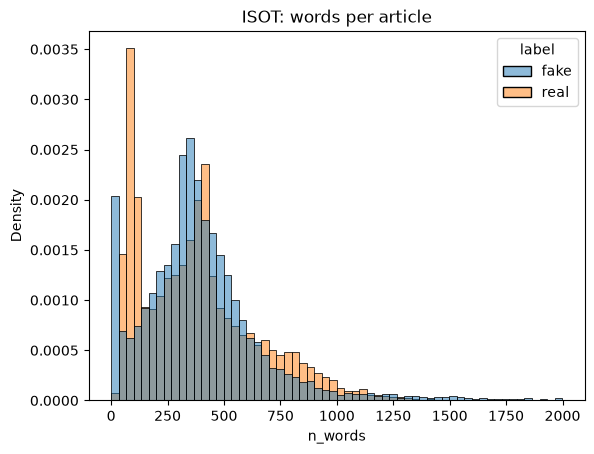

In [10]:
sns.histplot(data=isot[isot["n_words"] < 2000], x="n_words", hue="label", bins=60, stat="density", common_norm=False)
plt.title("ISOT: words per article")
plt.savefig(FIGURES_DIR / "02_length_isot.png", dpi=120)
plt.show()

In [11]:
wel.groupby("label")[["n_words", "n_title_words"]].median()

,n_words,n_title_words
label,,
fake,369.0,13.0
real,427.0,11.0


In [12]:
pd.crosstab(isot["subject"], isot["label"])

label,fake,real
subject,,
Government News,1570,0
Middle-east,778,0
News,9050,0
US_News,783,0
left-news,4459,0
politics,6841,0
politicsNews,0,11272
worldnews,0,10145


In [16]:
isot["date_parsed"] = pd.to_datetime(isot["date"].str.strip(), format="mixed", errors="coerce")
print(isot.groupby('label')["date_parsed"].agg(["min", "max", "count"]))
print(isot.loc[isot["date_parsed"].isna(), "date"].head())

             min        max  count
label                             
fake  2015-03-31 2018-02-19  23471
real  2016-01-13 2017-12-31  21417
9358     https://100percentfedup.com/served-roy-moore-v...
15507    https://100percentfedup.com/video-hillary-aske...
15508    https://100percentfedup.com/12-yr-old-black-co...
15839    https://fedup.wpengine.com/wp-content/uploads/...
15840    https://fedup.wpengine.com/wp-content/uploads/...
Name: date, dtype: str


In [19]:
checks = pd.DataFrame({
    "has_(Reuters)": isot["text"].str.contains("(Reuters)", regex=False),
    "title_starts_with_space": isot["title"].str.startswith(" "),
    "split_apostrophe": isot["text"].str.contains(r"\b\w+n t\b"),
    "title_has_CAPS_word": isot["title"].str.contains(r"\b[A-Z]{4,}\b"),
    "title_has_video": isot["title"].str.contains("video", case=False, regex=False),
})
(checks.groupby(isot["label"]).mean() * 100).round(1)

,has_(Reuters),title_starts_with_space,split_apostrophe,title_has_CAPS_word,title_has_video
label,,,,,
fake,0.0,38.5,62.6,79.6,35.7
real,99.2,0.0,8.1,2.5,0.2


In [20]:
from collections import Counter

from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))


def top_words(texts, n=15, stop=frozenset()):
    counts = Counter()
    for t in texts.fillna("").str.lower():
        counts.update(w for w in t.split() if w not in stop)
    return counts.most_common(n)

In [21]:
print(top_words(isot.loc[isot["label"] == "fake", "text"]))
print(top_words(isot.loc[isot["label"] == "real", "text"]))

[('the', 525528), ('to', 288565), ('of', 235161), ('and', 222329), ('a', 209598), ('in', 162846), ('that', 144901), ('s', 128331), ('is', 107720), ('for', 91066), ('on', 79829), ('he', 76896), ('it', 70359), ('was', 66944), ('trump', 65511)]
[('the', 477832), ('to', 244369), ('of', 204654), ('a', 196601), ('and', 180796), ('in', 179501), ('on', 107739), ('that', 84922), ('for', 79112), ('said', 72035), ('is', 54706), ('with', 54074), ('he', 52548), ('was', 47762), ('by', 47484)]


In [22]:
print(top_words(isot.loc[isot["label"] == "fake", "text"], stop=STOP))
print(top_words(isot.loc[isot["label"] == "real", "text"], stop=STOP))

[('trump', 65511), ('would', 23261), ('people', 22359), ('president', 22080), ('one', 21561), ('said', 21221), ('like', 16858), ('donald', 16800), ('obama', 16043), ('clinton', 15614), ('also', 14771), ('new', 13941), ('even', 13515), ('hillary', 12584), ('white', 12235)]
[('said', 72035), ('u.s.', 38276), ('trump', 36485), ('would', 31361), ('-', 31059), ('president', 23399), ('said.', 21583), ('(reuters)', 21239), ('new', 16578), ('also', 15870), ('state', 15608), ('united', 15521), ('government', 15319), ('house', 14550), ('republican', 14500)]
